# Keypoints

This example shows how to augment an image together with keypoints, e.g. for landmark detection.
The keypoints are transformed with the same geometric transforms as the image, so they stay at the same
image features.

The image comes with [scikit-image](https://scikit-image.org), and the keypoints are corners found by the Harris
corner detector.

In [1]:
%matplotlib inline
# JPEG keeps the notebook small, since the figures are photos
%config InlineBackend.figure_formats = ['jpeg']
import random

import cv2
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import patches

import solt
import solt.transforms as slt

# SOLT samples the transforms with the `random` module
random.seed(42)
np.random.seed(42)

from skimage import color, data, feature

## Getting the data

In [2]:
img = data.astronaut()
corners = feature.corner_peaks(feature.corner_harris(color.rgb2gray(img)), min_distance=12, threshold_rel=0.02)
# scikit-image returns (row, column), while SOLT uses (x, y)
kpts = corners[:, ::-1].astype(float)
print(f"Image: {img.shape}, {len(kpts)} keypoints")

Image: (512, 512, 3), 61 keypoints


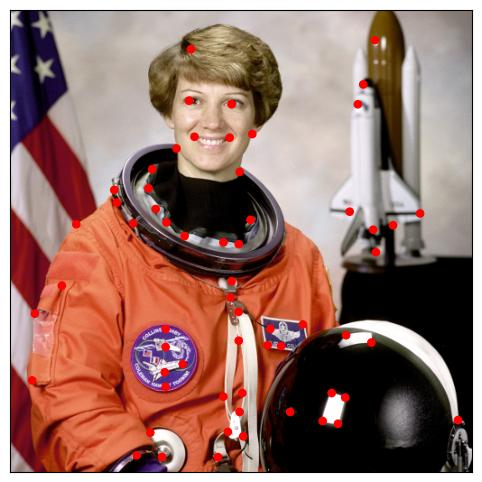

In [3]:
def show_keypoints(ax, img, kpts, radius=4):
    ax.imshow(img)
    for k in kpts:
        ax.add_patch(patches.Circle(k, radius=radius, color='r'))
    ax.set_xticks([])
    ax.set_yticks([])


fig, ax = plt.subplots(1, 1, figsize=(6, 6))
show_keypoints(ax, img, kpts)
plt.show()

## Wrapping the data into `SOLT` format

In [4]:
# Let's first wrap our keypoints into a keypoints container, which knows the size of the image (height, width)
kpts_wrapped = solt.Keypoints(kpts, img.shape[0], img.shape[1])
# Then, we wrap the image and the keypoints into a DataContainer
dc = solt.DataContainer((img, kpts_wrapped), 'IP')

## Simple pipeline

In [5]:
stream = solt.Stream([
    slt.Rotate(angle_range=(-20, 20), p=1),
    slt.Crop(384, crop_mode='r'),
])
print(stream.to_yaml())

stream:
  ignore_fast_mode: false
  interpolation: null
  optimize_stack: false
  padding: null
  shuffle: false
  transforms:
  - rotate:
      angle_range:
      - -20
      - 20
      ignore_fast_mode: false
      ignore_state: true
      interpolation:
      - bilinear
      - inherit
      p: 1
      padding:
      - z
      - inherit
  - crop:
      crop_mode: r
      crop_to:
      - 384
      - 384



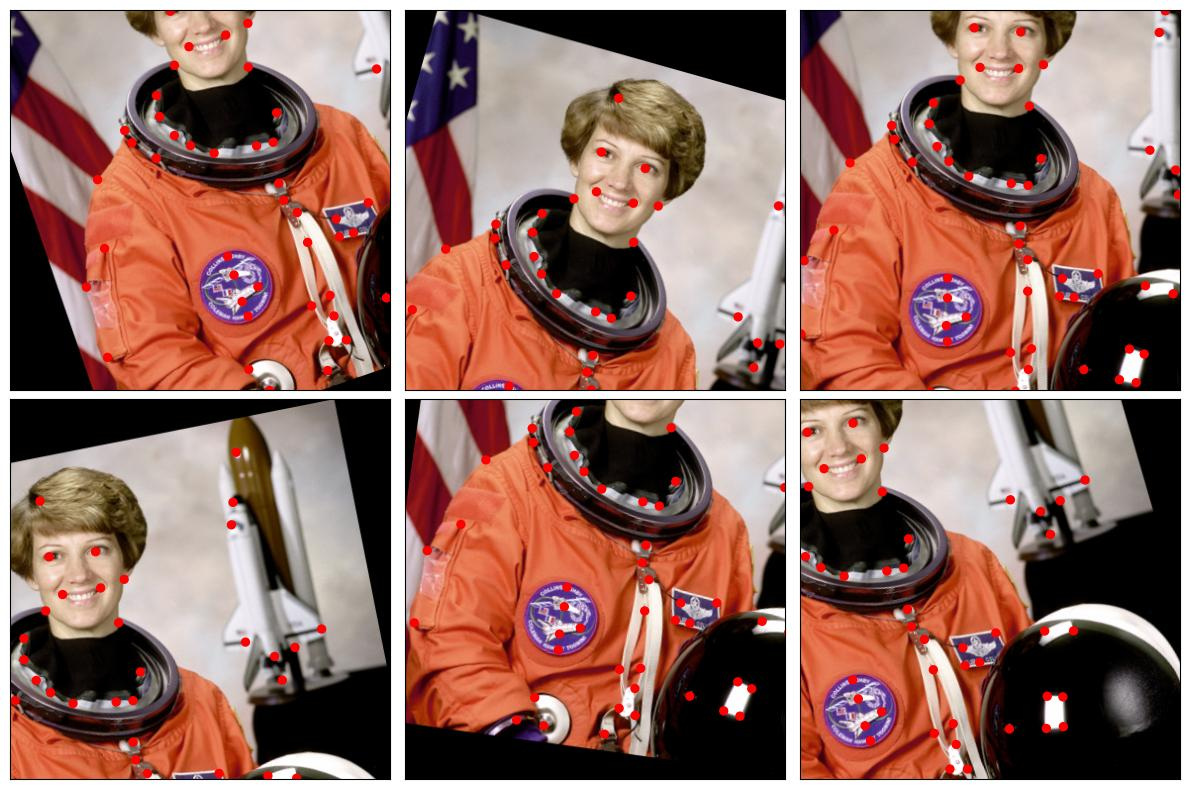

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax in axes.ravel():
    img_res, kpts_res = stream(dc, return_torch=False).data
    show_keypoints(ax, img_res, kpts_res.data)
plt.tight_layout()
plt.show()

## More complex pipeline

Here, the scaling, rotation and shearing are combined into a single projective transform, followed by
the intensity augmentations, which change only the image. `SelectiveStream` applies only one of its
transforms, selected at random.

In [7]:
stream = solt.Stream([
    slt.Projection(
        solt.Stream([
            slt.Scale(range_x=(0.5, 1.3), p=1),
            slt.Rotate(angle_range=(-90, 90), p=1),
            slt.Shear(range_x=(-0.5, 0.5), range_y=None, p=1),
        ]),
        v_range=(1e-6, 9e-4)),
    slt.GammaCorrection(p=0.5, gamma_range=(0.5, 3)),
    solt.SelectiveStream([
        slt.Blur(p=0.5, blur_type='g', k_size=(11, 21, 31), gaussian_sigma=(1, 10)),
        slt.Blur(p=0.5, blur_type='m', k_size=(11, 21, 31)),
    ]),
    solt.SelectiveStream([
        slt.SaltAndPepper(p=1),
        slt.Noise(p=1),
    ]),
    slt.Pad(600, 'z'),
    slt.Crop(600, crop_mode='c'),
    slt.Crop(512, crop_mode='r'),
])
print(stream.to_yaml())

stream:
  ignore_fast_mode: false
  interpolation: null
  optimize_stack: false
  padding: null
  shuffle: false
  transforms:
  - projection:
      affine_transforms:
        stream:
          ignore_fast_mode: false
          interpolation: null
          optimize_stack: false
          padding: null
          shuffle: false
          transforms:
          - scale:
              ignore_fast_mode: false
              ignore_state: true
              interpolation:
              - bilinear
              - inherit
              p: 1
              padding:
              - z
              - inherit
              range_x:
              - 0.5
              - 1.3
              range_y: null
              same: true
          - rotate:
              angle_range:
              - -90
              - 90
              ignore_fast_mode: false
              ignore_state: true
              interpolation:
              - bilinear
              - inherit
              p: 1
              padding:
    

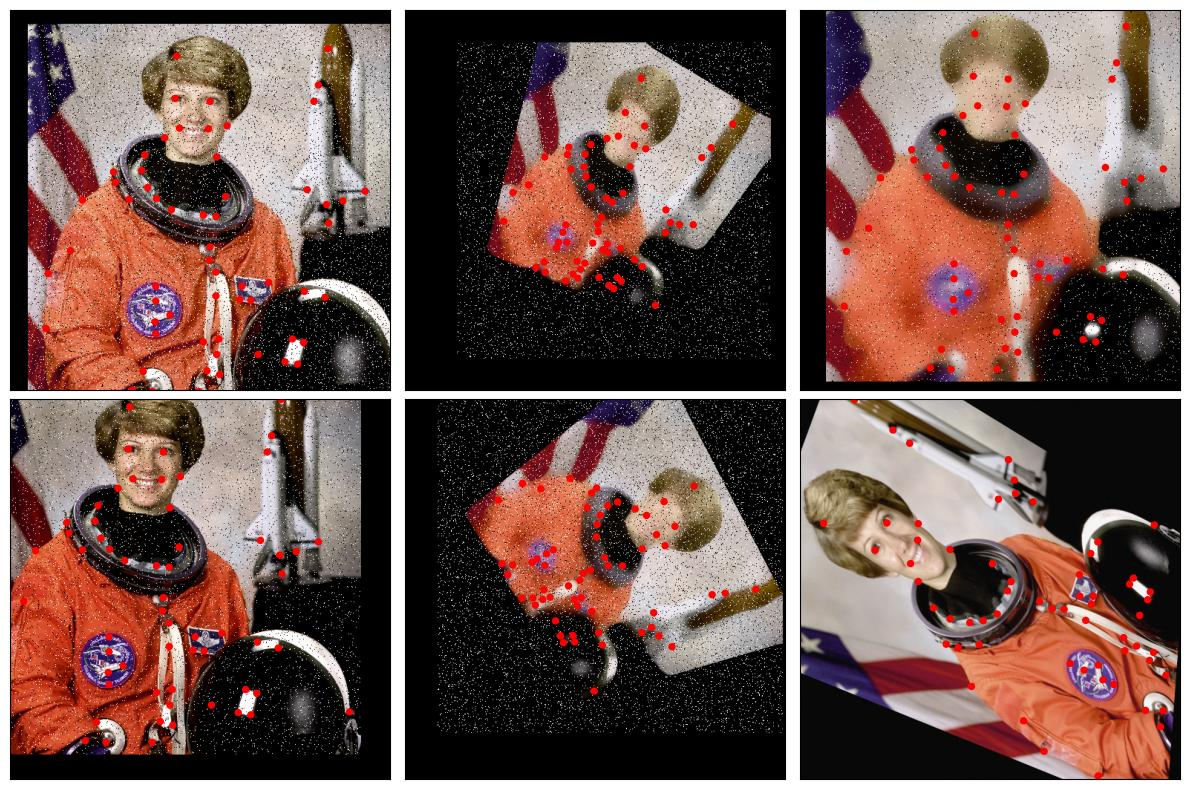

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax in axes.ravel():
    img_res, kpts_res = stream(dc, return_torch=False).data
    show_keypoints(ax, img_res, kpts_res.data)
plt.tight_layout()
plt.show()